# Khắc phục Overfitting bằng Regularization (Ridge & Lasso)

Khi mô hình đa thức có bậc $M$ quá cao, các trọng số $w$ có xu hướng bùng nổ lên những giá trị khổng lồ để bẻ cong hàm số đi qua mọi điểm nhiễu. Kỹ thuật Điều chuẩn (Regularization) giải quyết vấn đề này bằng cách cộng thêm một **Hạng tử phạt (Penalty Term)** vào hàm mất mát $\mathcal{L}(w)$, buộc mô hình phải giữ các trọng số ở mức nhỏ.

**1. Ridge Regression (L2 Regularization):**
Phạt bình phương các trọng số. Hàm mất mát trở thành:
$$\mathcal{L}_{Ridge}(w) = \frac{1}{2N} ||\Phi w - y||_2^2 + \frac{\alpha}{2} ||w||_2^2$$
Nghiệm giải tích (Normal Equation) được điều chỉnh thành:
$$w^* = (\Phi^T \Phi + \alpha I)^{-1} \Phi^T y$$
*(Lưu ý: Không áp dụng phạt cho hệ số tự do $w_0$)*

**2. Lasso Regression (L1 Regularization):**
Phạt giá trị tuyệt đối của các trọng số:
$$\mathcal{L}_{Lasso}(w) = \frac{1}{2N} ||\Phi w - y||_2^2 + \alpha ||w||_1$$
Đạo hàm của $||w||_1$ là hàm $sign(w)$. L1 Regularization không chỉ giảm độ lớn của $w$ mà còn ép nhiều trọng số về chính xác $0$, giúp chọn lọc đặc trưng (Feature Selection).

In [2]:
import numpy as np

class RidgeRegression:
    """Hồi quy Ridge với nghiệm giải tích (Normal Equation)."""
    def __init__(self, alpha=1.0, fit_intercept=True):
        self.alpha = alpha
        self.fit_intercept = fit_intercept

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        Phi = np.hstack([np.ones((X.shape[0], 1)), X]) if self.fit_intercept else X
        
        # Ma trận đơn vị I
        I = np.eye(Phi.shape[1])
        if self.fit_intercept:
            I[0, 0] = 0.0 # Bỏ qua phạt cho w0 (Intercept)
            
        # Nghiệm đóng với hạng tử L2
        w_opt = np.linalg.inv(Phi.T @ Phi + self.alpha * I) @ Phi.T @ y
        
        if self.fit_intercept:
            self.intercept, self.weights = float(w_opt[0, 0]), w_opt[1:].flatten()
        else:
            self.intercept, self.weights = 0.0, w_opt.flatten()
        return self
        
    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

class LassoRegressionGD:
    """Hồi quy Lasso tối ưu bằng Gradient Descent (Subgradient)."""
    def __init__(self, alpha=0.1, lr=0.01, epochs=10000, fit_intercept=True):
        self.alpha = alpha
        self.lr = lr
        self.epochs = epochs
        self.fit_intercept = fit_intercept

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        N = X.shape[0]
        Phi = np.hstack([np.ones((N, 1)), X]) if self.fit_intercept else X
        w = np.zeros((Phi.shape[1], 1))
        
        for _ in range(self.epochs):
            y_pred = Phi @ w
            grad_mse = (Phi.T @ (y_pred - y)) / N
            grad_l1 = self.alpha * np.sign(w)
            if self.fit_intercept:
                grad_l1[0, 0] = 0.0 # Bỏ qua phạt cho w0
                
            w -= self.lr * (grad_mse + grad_l1)
            
        if self.fit_intercept:
            self.intercept, self.weights = float(w[0, 0]), w[1:].flatten()
        else:
            self.intercept, self.weights = 0.0, w.flatten()
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

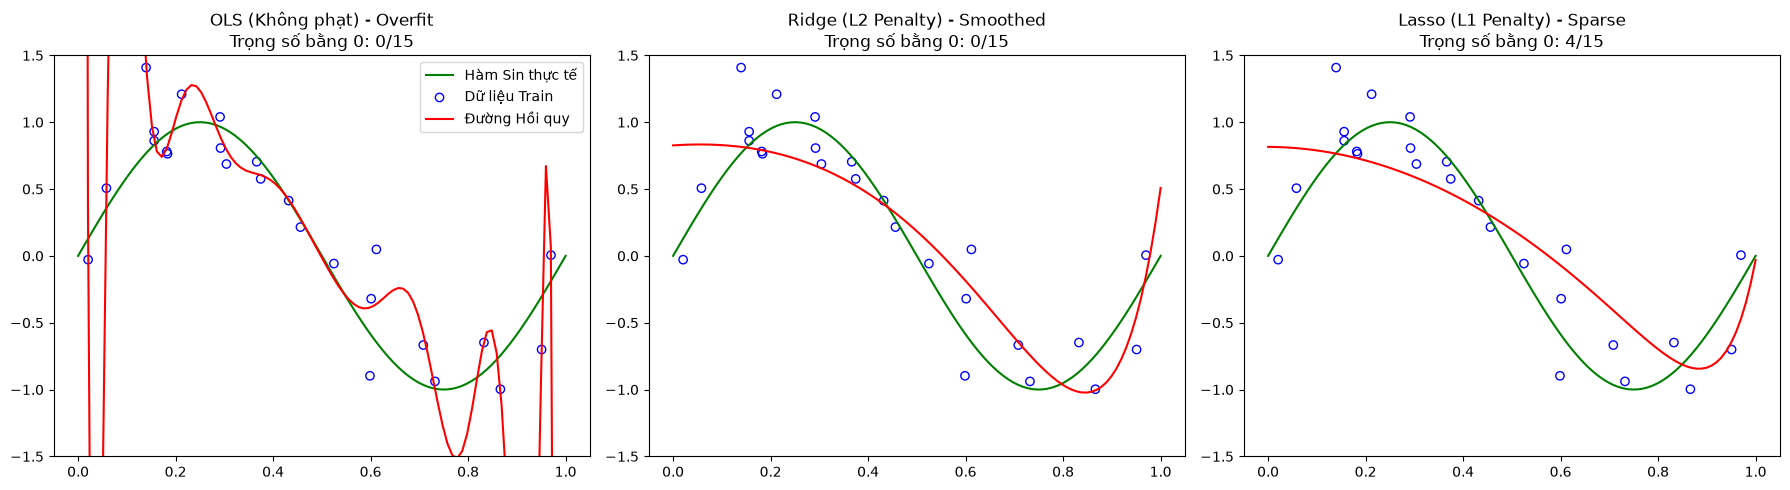

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from utils.preprocessing import PolynomialFeatures, StandardScaler

# -------------------------------------------------------------------------
# Tái định nghĩa nhanh Class Linear Regression (OLS) để làm Baseline so sánh
# -------------------------------------------------------------------------
class LinearRegressionNormalEq:
    def __init__(self, fit_intercept=True):
        self.fit_intercept = fit_intercept
        self.weights = None
        self.intercept = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        Phi = np.hstack([np.ones((X.shape[0], 1), dtype=X.dtype), X]) if self.fit_intercept else X
        w_opt = np.linalg.pinv(Phi) @ y
        if self.fit_intercept:
            self.intercept = float(w_opt[0, 0])
            self.weights = w_opt[1:].flatten()
        else:
            self.intercept = 0.0
            self.weights = w_opt.flatten()
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

# 1. Sinh dữ liệu 
np.random.seed(42)
N = 25
X_train = np.sort(np.random.rand(N, 1), axis=0)
y_train = np.sin(2 * np.pi * X_train).flatten() + np.random.randn(N) * 0.25
X_test = np.linspace(0, 1, 100).reshape(-1, 1)
y_true = np.sin(2 * np.pi * X_test).flatten()

# 2. Tạo đặc trưng đa thức bậc 15 và Chuẩn hóa (Bắt buộc với Regularization)
poly = PolynomialFeatures(degree=15)
scaler = StandardScaler()

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# 3. Huấn luyện 3 mô hình
model_ols = LinearRegressionNormalEq().fit(X_train_scaled, y_train)
model_ridge = RidgeRegression(alpha=0.5).fit(X_train_scaled, y_train)
model_lasso = LassoRegressionGD(alpha=0.05, lr=0.1, epochs=5000).fit(X_train_scaled, y_train)

# 4. Trực quan hóa
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ["OLS (Không phạt) - Overfit", "Ridge (L2 Penalty) - Smoothed", "Lasso (L1 Penalty) - Sparse"]
models = [model_ols, model_ridge, model_lasso]

for i, ax in enumerate(axes):
    y_pred = models[i].predict(X_test_scaled)
    ax.plot(X_test, y_true, color='green', label='Hàm Sin thực tế')
    ax.scatter(X_train, y_train, color='blue', facecolors='none', label='Dữ liệu Train')
    ax.plot(X_test, y_pred, color='red', label='Đường Hồi quy')
    
    # Tính số lượng trọng số bị ép về 0 (cho Lasso)
    zero_weights = np.sum(np.abs(models[i].weights) < 1e-3)
    
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(f"{titles[i]}\nTrọng số bằng 0: {zero_weights}/15")
    if i == 0: ax.legend()

plt.tight_layout()
plt.show()